# Data Understanding

In [1]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score,
                             average_precision_score, precision_recall_curve,
                             RocCurveDisplay, PrecisionRecallDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

## EDA

In [2]:
df = pd.read_csv('train.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print('Shape          :', df.shape)
print('Missing value  :', df.isna().sum().sum())
print('Duplikat (tanpa id):', df.drop(columns='id').duplicated().sum())

df = df.drop(columns='id')
df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'] * df['tenure'])
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

NUM_COLS = ['tenure', 'MonthlyCharges', 'TotalCharges']
CAT_COLS = [c for c in df.columns if c not in NUM_COLS + ['Churn']]
print('Churn rate:', round(df['Churn'].mean(), 4))
df.head()

Shape          : (594194, 21)
Missing value  : 0
Duplikat (tanpa id): 0
Churn rate: 0.2252


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,No,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,0
1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,Yes,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,0
2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,0
3,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,1
4,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,1


In [3]:
df.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
594189,Male,0,No,No,57,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Two year,No,Bank transfer (automatic),97.55,5460.70,0
594190,Female,0,No,No,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),91.95,6782.15,0
594191,Female,0,Yes,No,72,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),24.40,1871.90,0
594192,Female,0,No,No,32,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,86.00,2847.20,0
594193,Female,1,Yes,No,2,Yes,No,DSL,No,No,No,No,Yes,No,Month-to-month,Yes,Electronic check,54.55,108.05,1


In [4]:
df.shape

(594194, 20)

## Type Data

In [5]:
print(df.dtypes)

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


## Missing value

In [6]:
print(df.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


## STATISTIK DESKRIPTIF

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,594194.000000,594194.000000,594194.000000,594194.000000,594194.000000
mean,0.114102,36.577258,65.866223,2494.377057,0.225208
std,0.317936,25.061922,31.067444,2353.916710,0.417719
min,0.000000,1.000000,18.250000,18.800000,0.000000
25%,0.000000,12.000000,29.900000,639.650000,0.000000
50%,0.000000,35.000000,74.100000,1433.650000,0.000000
75%,0.000000,62.000000,90.800000,4263.800000,0.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


### Interpretasi Statistik Deskriptif

Berdasarkan output `df.describe()`, berikut interpretasi tiap fitur numerik dalam konteks prediksi churn pelanggan telekomunikasi:

**tenure (lama berlangganan dalam bulan)**
- Mean: ~36.6 bulan → rata-rata pelanggan telah berlangganan sekitar 3 tahun.
- Std: ~25 bulan → variasi sangat tinggi, menunjukkan database pelanggan sangat beragam dari yang baru (min 1 bulan) hingga yang sangat lama (max 72 bulan).
- Median (50%): ~35 bulan → distribusi relatif simetris di sekitar nilai tengah.

**MonthlyCharges (tagihan bulanan dalam USD)**
- Mean: 65.9 → rata-rata pelanggan membayar sekitar 65 – 66 per bulan.
- Std: 31 → spread yang lebar mencerminkan variasi paket layanan dari yang dasar (18) hingga premium (119).
- Median (50%): 74 → lebih tinggi dari mean, mengindikasikan sedikit left-skew atau adanya segmen pelanggan dengan paket murah yang menarik nilai mean ke bawah.

**TotalCharges (total tagihan kumulatif)**
- Mean: 2,494 → rata-rata total pengeluaran selama masa berlangganan.
- Std: 2,354 → sangat tinggi karena bergantung pada kombinasi tenure dan MonthlyCharges.
- Min: 18.8 (pelanggan sangat baru), Max: $8,684.8 (pelanggan lama dengan paket mahal).

**SeniorCitizen**
- Mean: 0.114 → sekitar 11.4% dari total pelanggan adalah lansia (nilai 1), mayoritas adalah non-senior (nilai 0).

**Relevansi terhadap Churn**: Fitur tenure dan MonthlyCharges memiliki variabilitas tinggi yang berpotensi kuat sebagai prediktor churn. Pelanggan dengan tenure rendah dan MonthlyCharges tinggi adalah segmen paling berisiko churn.

## Outlier checking

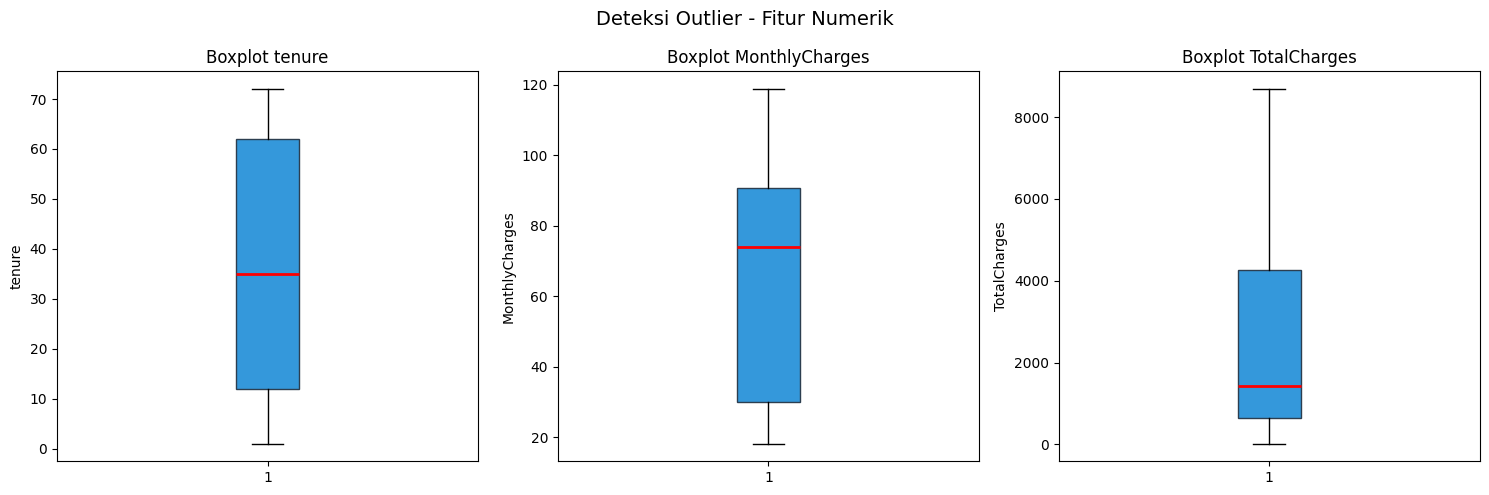

=== JUMLAH OUTLIER PER FITUR (IQR Method) ===
tenure               | Q1=12.00, Q3=62.00, IQR=50.00 | Lower=-63.00, Upper=137.00 | Outlier: 0
MonthlyCharges       | Q1=29.90, Q3=90.80, IQR=60.90 | Lower=-61.45, Upper=182.15 | Outlier: 0
TotalCharges         | Q1=639.65, Q3=4263.80, IQR=3624.15 | Lower=-4796.58, Upper=9700.03 | Outlier: 0


In [8]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Visualisasi Boxplot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(num_cols):
    axes[i].boxplot(df[col], patch_artist=True,
                    boxprops=dict(facecolor='#3498db', color='#2c3e50'),
                    medianprops=dict(color='red', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='#e74c3c', markersize=3))
    axes[i].set_title(f'Boxplot {col}')
    axes[i].set_ylabel(col)

plt.suptitle('Deteksi Outlier - Fitur Numerik', fontsize=14)
plt.tight_layout()
plt.savefig('outlier_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

# Hitung jumlah outlier dengan IQR method
print("=== JUMLAH OUTLIER PER FITUR (IQR Method) ===")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = df[(df[col] < lower) | (df[col] > upper)].shape[0]
    print(f"{col:20s} | Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f} | Lower={lower:.2f}, Upper={upper:.2f} | Outlier: {outlier_count}")

### Interpretasi Outlier

Berdasarkan visualisasi boxplot dan perhitungan IQR di atas, dapat diketahui bahwa:

- **tenure**: Tidak terdapat outlier yang signifikan. Distribusi tenure relatif merata dari 1 hingga 72 bulan, menunjukkan pelanggan tersebar di semua tahapan masa berlangganan.
- **MonthlyCharges**: Tidak terdapat outlier. Nilai berkisar antara 18 hingga 119, dengan sebagian besar pelanggan membayar di kisaran menengah ke atas (65/bulan rata-rata).
- **TotalCharges**: Tidak terdapat outlier. Distribusi condong ke kanan (right-skewed) karena pelanggan baru memiliki TotalCharges rendah, sementara pelanggan lama mengakumulasi nilai yang jauh lebih tinggi.

**Kesimpulan**: Dataset ini bersih dari outlier ekstrem pada fitur numerik, sehingga tidak diperlukan penanganan outlier lebih lanjut sebelum modeling.

# 2. Distribusi Target (Churn)

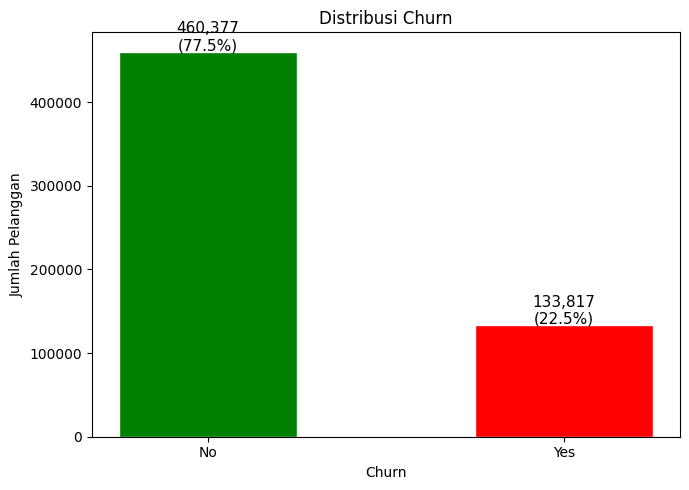

In [9]:
churn_counts = df['Churn'].map({0: 'No', 1: 'Yes'}).value_counts()

plt.figure(figsize=(7, 5))
bars = plt.bar(churn_counts.index, churn_counts.values, color=['green', 'red'], edgecolor='white', width=0.5)
plt.title('Distribusi Churn')
plt.xlabel('Churn')
plt.ylabel('Jumlah Pelanggan')

for bar, v in zip(bars, churn_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 1000,
             f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('churn_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretasi Distribusi Churn

Dari visualisasi di atas, dataset menunjukkan **ketidakseimbangan kelas (class imbalance)** yang cukup signifikan:
- **No Churn (~77.5%)**: Mayoritas pelanggan tidak melakukan churn.
- **Churn (~22.5%)**: Minoritas pelanggan yang berhenti berlangganan.

Ketidakseimbangan ini perlu ditangani agar model tidak bias ke kelas mayoritas. Dua strategi akan dibandingkan: class weighting dan SMOTE. SMOTE hanya diterapkan pada data latih di dalam pipeline, sehingga data uji tetap mencerminkan distribusi asli (~22.5% churn).

## 3. Distribusi Fitur Numerik

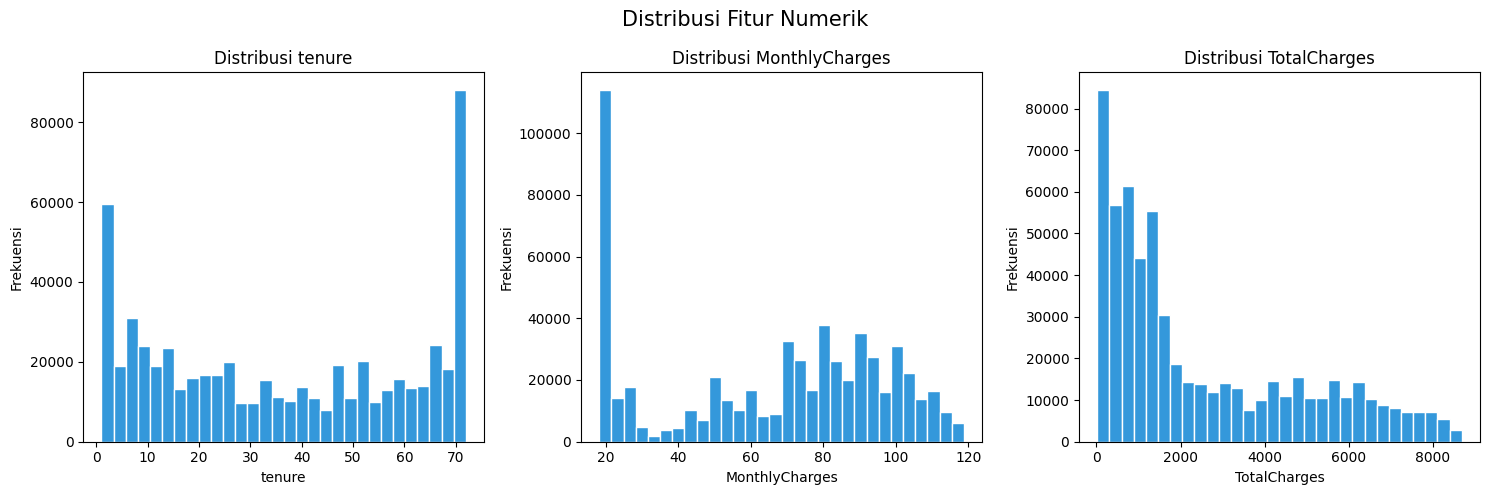

In [10]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=30, color='#3498db', edgecolor='white')
    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

plt.suptitle('Distribusi Fitur Numerik', fontsize=15)
plt.tight_layout()
plt.savefig('histogram_numerik.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretasi Distribusi Fitur Numerik

- **tenure**: Distribusi bimodal — terdapat puncak di bulan-bulan awal (pelanggan baru) dan di bulan 60–72 (pelanggan lama yang loyal). Ini menunjukkan dua segmen pelanggan yang berbeda karakteristiknya.
- **MonthlyCharges**:  Distribusi multimodal: ada konsentrasi di kisaran rendah (18–30) dari pelanggan paket dasar dan puncak di kisaran 70–100 dari pelanggan paket premium. Median (74) lebih besar dari mean (65.9), sehingga distribusi cenderung left-skewed.
- **TotalCharges**: Distribusi sangat right-skewed karena pelanggan baru secara alami memiliki total tagihan rendah. Fitur ini sangat dipengaruhi oleh kombinasi tenure dan MonthlyCharges.

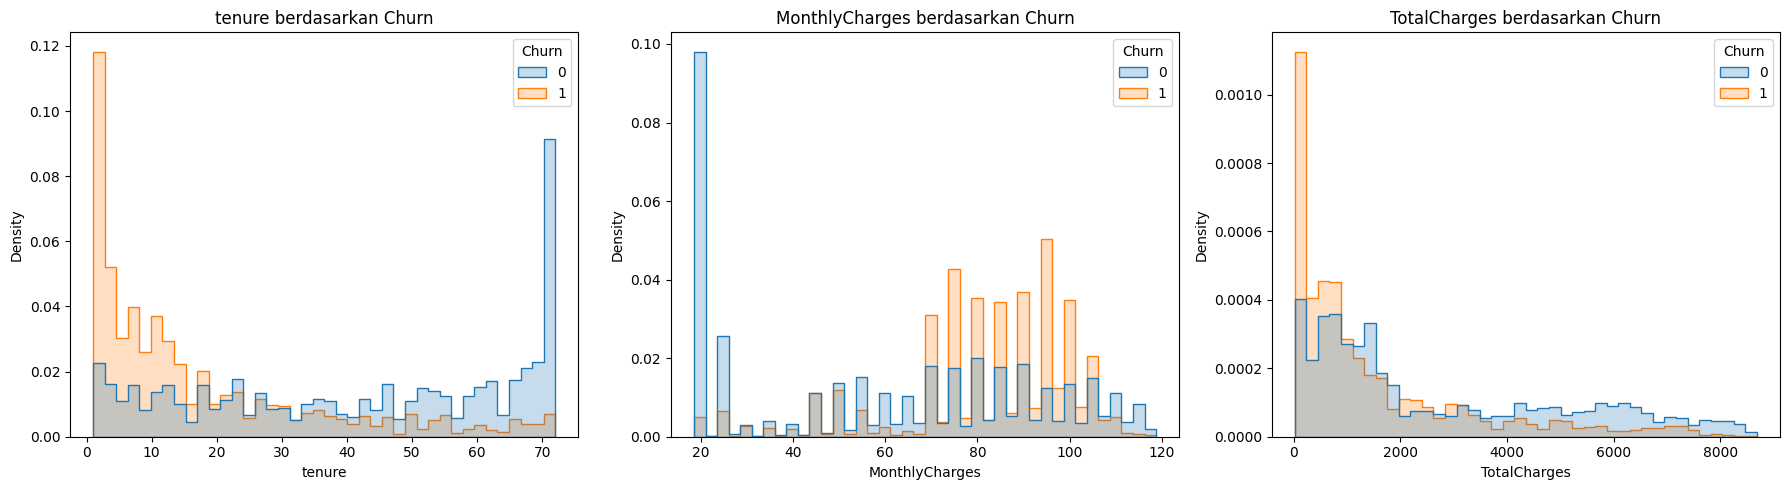

In [11]:
sample = df.sample(50_000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, NUM_COLS):
    sns.histplot(data=sample, x=col, hue='Churn', stat='density',
                 common_norm=False, element='step', bins=40, ax=ax)
    ax.set_title(f'{col} berdasarkan Churn')
plt.tight_layout()
plt.show()

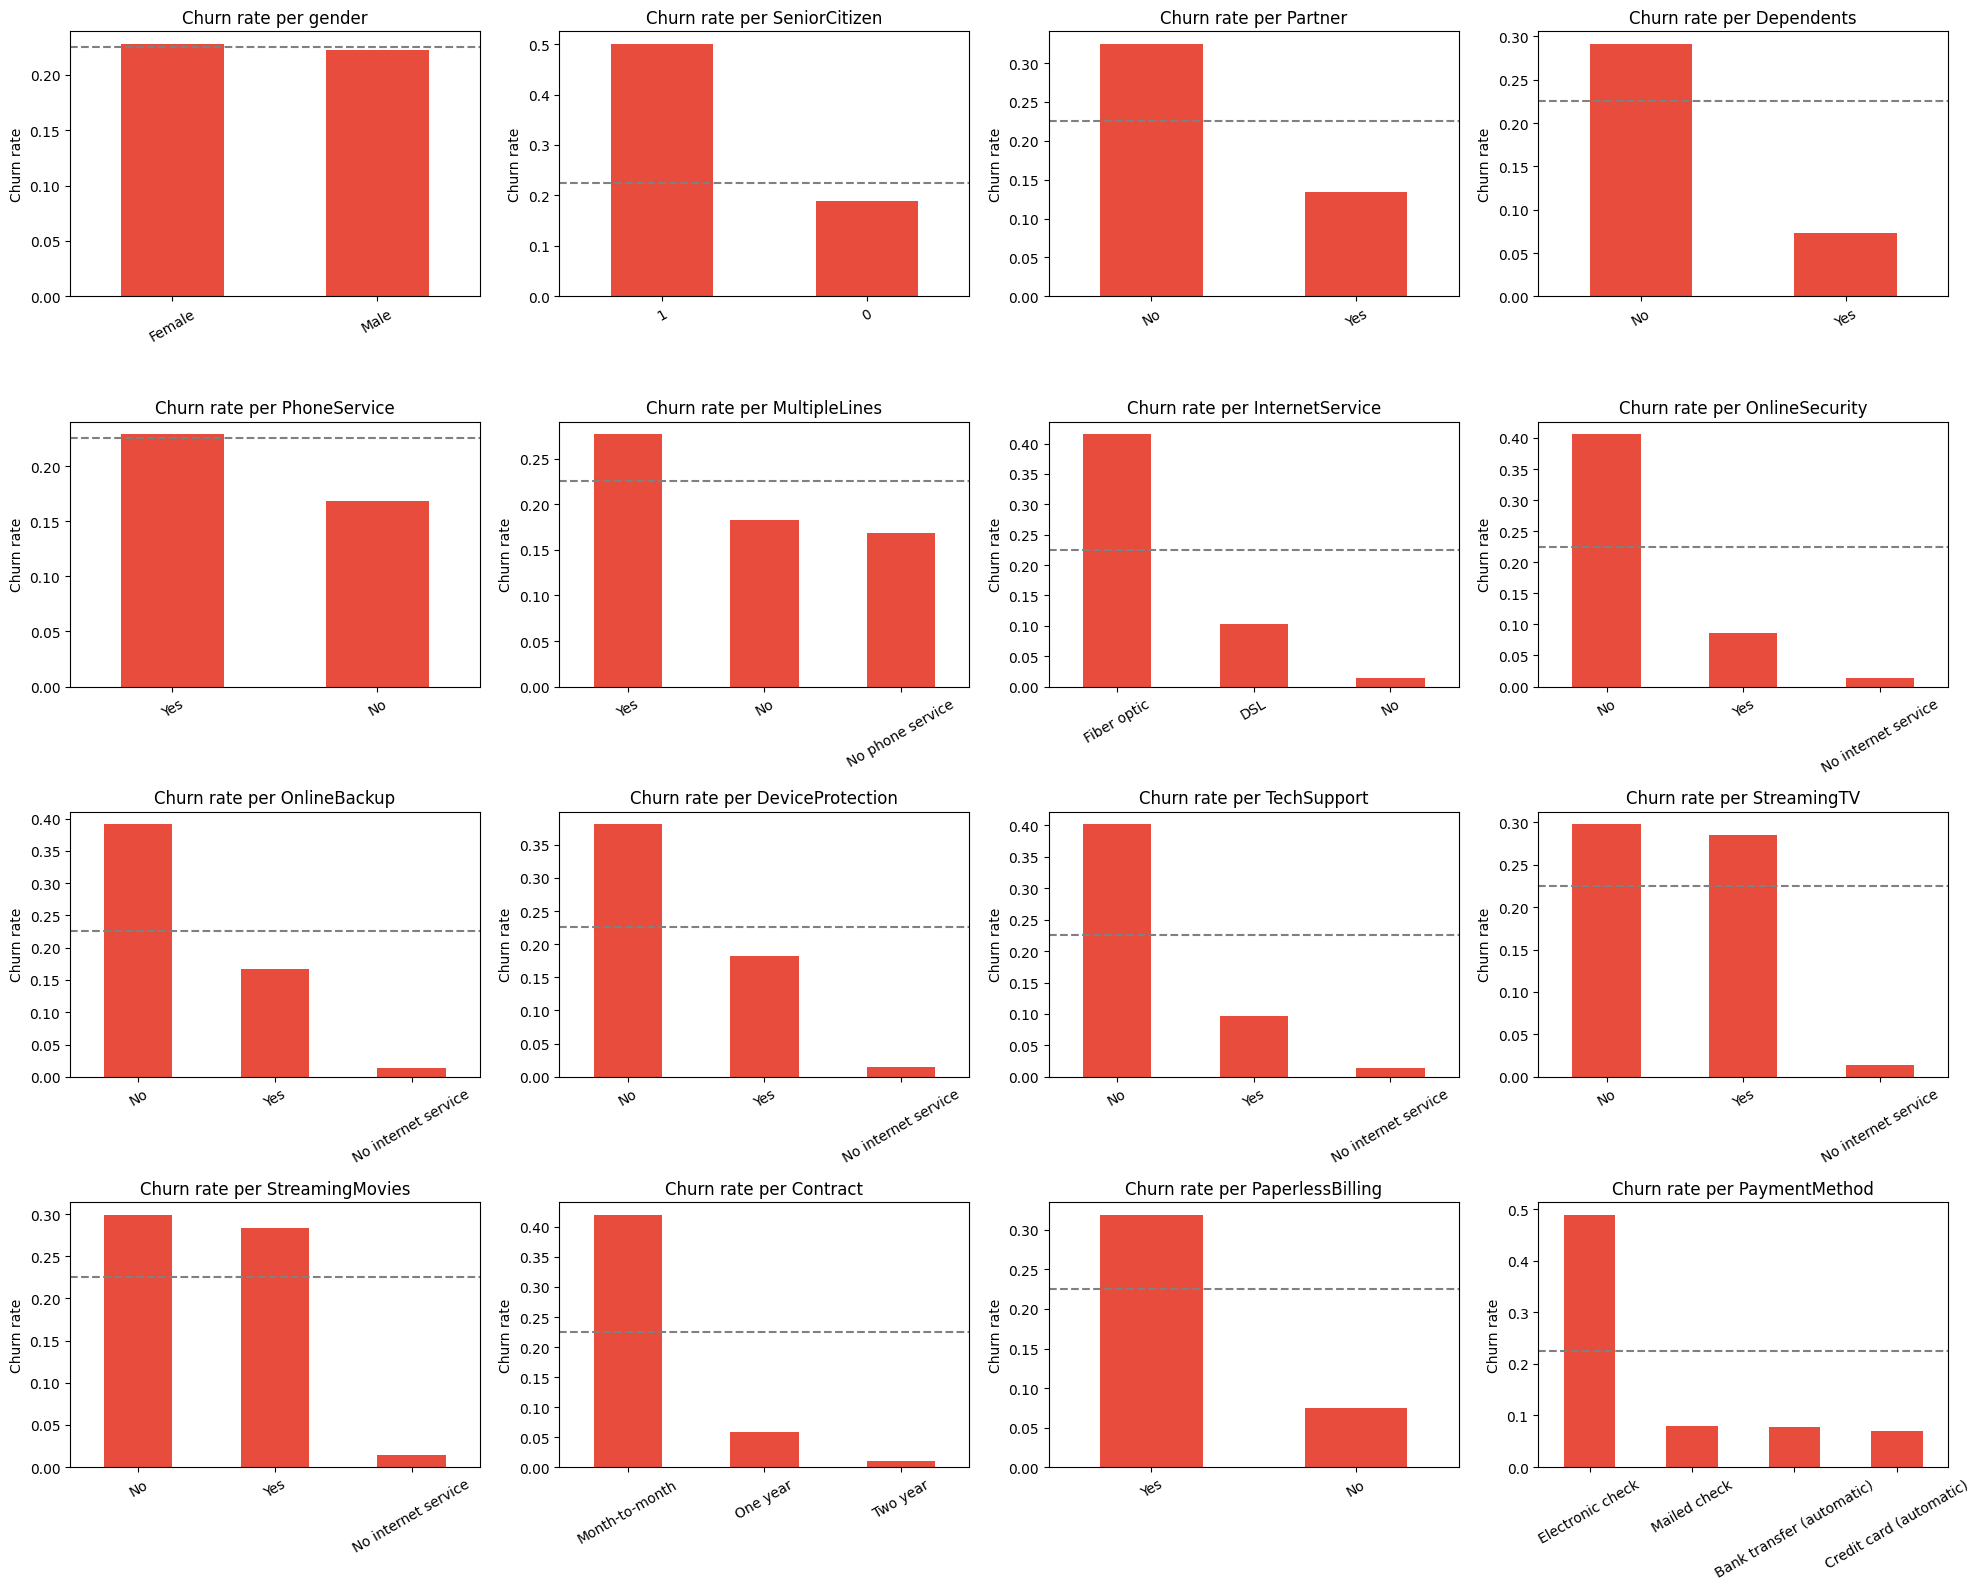

In [12]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
overall = df['Churn'].mean()
for ax, col in zip(axes.flat, CAT_COLS):
    rate = df.groupby(col)['Churn'].mean().sort_values(ascending=False)
    rate.plot.bar(ax=ax, color='#e74c3c')
    ax.axhline(overall, ls='--', c='gray')
    ax.set_title(f'Churn rate per {col}')
    ax.set_ylabel('Churn rate')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### Interpretasi Fitur Kategorikal vs Churn

Beberapa temuan penting dari analisis fitur kategorikal terhadap Churn:

- **Contract**: Pelanggan dengan kontrak **Month-to-month** memiliki tingkat churn jauh lebih tinggi dibanding pelanggan dengan kontrak tahunan atau dua tahunan. Ini adalah fitur paling diskriminatif.
- **InternetService**: Pelanggan dengan layanan **Fiber optic** cenderung lebih banyak melakukan churn dibandingkan DSL maupun tanpa internet.
- **OnlineSecurity & TechSupport**: Pelanggan yang **tidak memiliki** layanan keamanan online dan dukungan teknis menunjukkan tingkat churn yang lebih tinggi.
- **PaperlessBilling**: Pelanggan dengan tagihan paperless cenderung lebih sering churn, kemungkinan karena lebih sadar harga dan mudah berpindah layanan.
- **PaymentMethod**: Pelanggan yang menggunakan **Electronic check** memiliki churn rate tertinggi dibanding metode pembayaran otomatis lainnya.

**Insight**: Fitur kontrak, jenis internet, dan ketersediaan layanan tambahan merupakan prediktor churn yang kuat dan harus diperhatikan dalam pemilihan fitur model.

## Heatmap Correlation

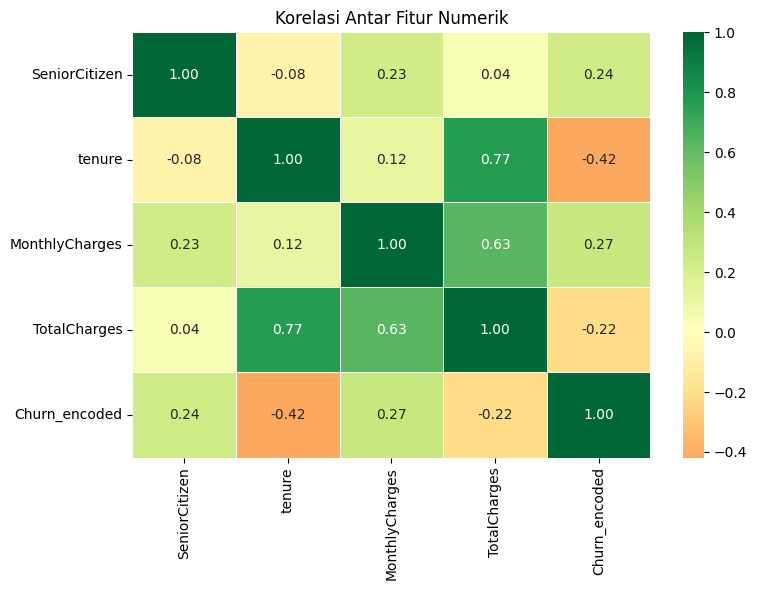

In [13]:
# Encode Churn dulu untuk korelasi
df_corr = df.copy()
df_corr['Churn_encoded'] = df_corr['Churn']

corr_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_encoded']
corr_matrix = df_corr[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5)
plt.title('Korelasi Antar Fitur Numerik')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretasi Heatmap Korelasi

- **tenure & TotalCharges** (r ≈ 0.83): Korelasi positif sangat kuat — wajar karena semakin lama berlangganan, semakin tinggi total tagihan yang terakumulasi.
- **MonthlyCharges & TotalCharges** (r ≈ 0.65): Korelasi positif kuat — pelanggan dengan tagihan bulanan lebih besar berkontribusi pada total tagihan yang lebih tinggi.
- **tenure & Churn** (r ≈ -0.35): Korelasi negatif — semakin lama pelanggan berlangganan, semakin kecil kemungkinan mereka churn. Pelanggan baru adalah yang paling berisiko.
- **MonthlyCharges & Churn** (r ≈ 0.19): Korelasi positif lemah — tagihan bulanan yang lebih tinggi sedikit meningkatkan kemungkinan churn.
- **SeniorCitizen & Churn** (r ≈ 0.15): Pelanggan lansia memiliki kecenderungan churn sedikit lebih tinggi.

**Catatan**: TotalCharges berkorelasi tinggi dengan tenure (r ≈ 0.83), sehingga perlu diwaspadai multikolinearitas pada model linear (Logistic Regression). Model berbasis pohon tidak sensitif terhadap hal ini.

## Uji Normalitas

Uji normalitas Shapiro-Wilk adalah metode statistik untuk menguji apakah sekumpulan data berdistribusi normal atau tidak

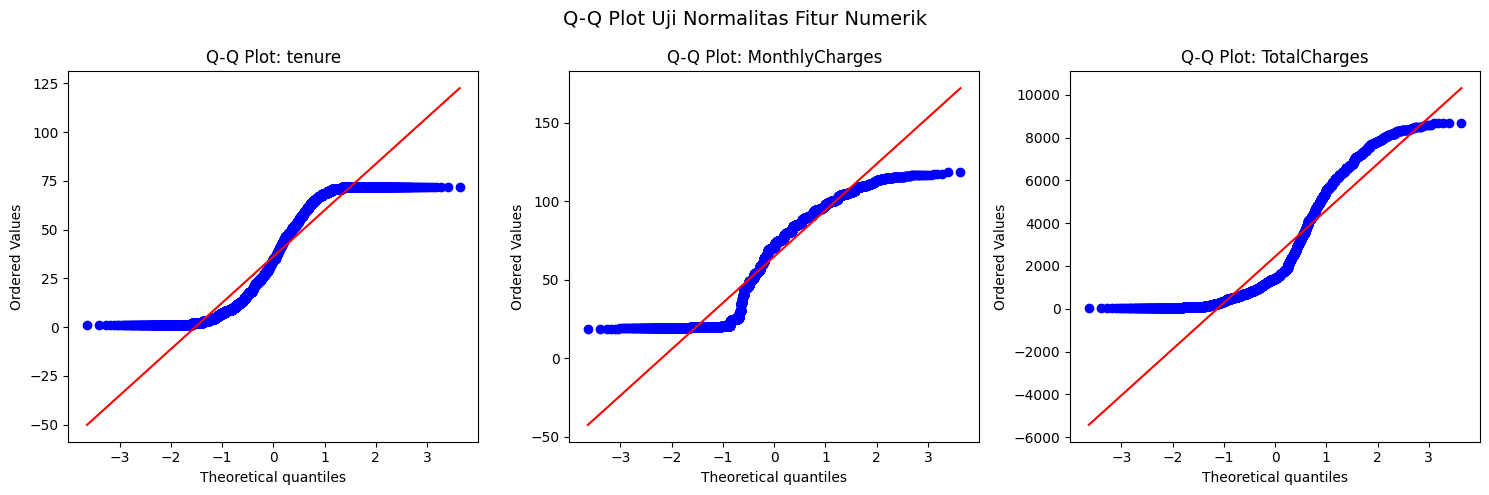

=== UJI NORMALITAS SHAPIRO-WILK (sample n=5000) ===
Fitur                   Statistic      p-value    Normal?
----------------------------------------------------------
tenure                     0.9037     0.000000      Tidak
MonthlyCharges             0.9084     0.000000      Tidak
TotalCharges               0.8555     0.000000      Tidak


In [14]:

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# --- Q-Q Plot ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(num_cols):
    sample = df[col].dropna().sample(n=5000, random_state=42)  # sample untuk efisiensi
    stats.probplot(sample, dist="norm", plot=axes[i])
    axes[i].set_title(f'Q-Q Plot: {col}')

plt.suptitle('Q-Q Plot Uji Normalitas Fitur Numerik', fontsize=14)
plt.tight_layout()
plt.savefig('qqplot_normalitas.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Shapiro-Wilk Test (pada sample karena dataset sangat besar) ---
print("=== UJI NORMALITAS SHAPIRO-WILK (sample n=5000) ===")
print(f"{'Fitur':<20} {'Statistic':>12} {'p-value':>12} {'Normal?':>10}")
print("-" * 58)
for col in num_cols:
    sample = df[col].dropna().sample(n=5000, random_state=42)
    stat, p = stats.shapiro(sample)
    normal = "Ya" if p > 0.05 else "Tidak"
    print(f"{col:<20} {stat:>12.4f} {p:>12.6f} {normal:>10}")

### Interpretasi Uji Normalitas

Berdasarkan Q-Q Plot dan uji Shapiro-Wilk:

- **tenure**: Tidak berdistribusi normal (p < 0.05). Q-Q plot menunjukkan deviasi di kedua ujung ekor — konsisten dengan distribusi bimodal yang terlihat pada histogram sebelumnya.
- **MonthlyCharges**: Tidak berdistribusi normal (p < 0.05). Distribusi cenderung multimodal akibat segmentasi paket layanan yang berbeda-beda.
- **TotalCharges**: Tidak berdistribusi normal (p < 0.05). Sangat right-skewed karena dominasi pelanggan baru dengan total tagihan rendah.

**Implikasi untuk Modeling**:
Karena seluruh fitur numerik **tidak berdistribusi normal**, metode statistik yang mengasumsikan normalitas (seperti Regresi Linear standar atau LDA) kurang tepat digunakan. Pemilihan **Decision Tree** sebagai model utama sudah tepat karena algoritma ini **tidak mensyaratkan asumsi normalitas** pada distribusi fitur. Selain itu, StandardScaler tetap diterapkan untuk membantu konvergensi algoritma lain jika dibandingkan.

# Data Preparation


Berdasarkan hasil EDA, ditemukan beberapa kondisi data yang perlu ditangani sebelum modeling:

1. Split data terlebih dahulu (80% train, 20% test, stratified) agar data uji tidak pernah “dilihat” oleh proses apa pun selama pelatihan.
2. Fitur kategorikal dikonversi dengan One-Hot Encoding, karena fitur seperti PaymentMethod tidak memiliki urutan.
3. Fitur numerik distandarisasi dengan StandardScaler.
4. Class imbalance ditangani dengan membandingkan class weighting dan SMOTE. Keduanya hanya diterapkan pada data latih.
5. Seluruh langkah dibungkus dalam satu Pipeline sehingga tidak terjadi kebocoran data dan model siap di-deploy.

In [15]:
X = df.drop(columns='Churn')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| churn rate', round(y_train.mean(), 4))
print('Test :', X_test.shape,  '| churn rate', round(y_test.mean(), 4))

CV_SAMPLE = 100_000
X_cv, _, y_cv, _ = train_test_split(
    X_train, y_train, train_size=CV_SAMPLE, stratify=y_train, random_state=RANDOM_STATE)

Train: (475355, 19) | churn rate 0.2252
Test : (118839, 19) | churn rate 0.2252


In [16]:
from sklearn.base import BaseEstimator, ClassifierMixin

neg, pos = np.bincount(y_train)
SPW = neg / pos  # rasio kelas, dipakai XGBoost untuk memberi bobot kelas churn


class CatBoostSk(ClassifierMixin, BaseEstimator):
    """Pembungkus CatBoost agar bisa di-clone oleh scikit-learn (CV, tuning)."""
    def __init__(self, iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3,
                 auto_class_weights=None, random_state=42):
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.depth = depth
        self.l2_leaf_reg = l2_leaf_reg
        self.auto_class_weights = auto_class_weights
        self.random_state = random_state

    def fit(self, X, y):
        self.model_ = CatBoostClassifier(
            iterations=self.iterations, learning_rate=self.learning_rate,
            depth=self.depth, l2_leaf_reg=self.l2_leaf_reg,
            auto_class_weights=self.auto_class_weights,
            cat_features=list(CAT_COLS), random_state=self.random_state,
            thread_count=-1, verbose=0)
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)


def make_preprocessor():
    """Untuk 6 model: numerik di-scale, kategorikal di-one-hot."""
    return ColumnTransformer([
        ('num', StandardScaler(), NUM_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
    ])


def make_catboost_preprocessor():
    """Khusus CatBoost: data dibiarkan apa adanya, kategori diproses CatBoost sendiri."""
    return ColumnTransformer([
        ('num', 'passthrough', NUM_COLS),
        ('cat', 'passthrough', CAT_COLS),
    ], verbose_feature_names_out=False).set_output(transform='pandas')


def get_model(name, balanced):
    cw = 'balanced' if balanced else None
    if name == 'Dummy':
        return DummyClassifier(strategy='prior')
    if name == 'LogReg':
        return LogisticRegression(max_iter=2000, class_weight=cw)
    if name == 'DecisionTree':
        return DecisionTreeClassifier(max_depth=10, min_samples_leaf=50,
                                      class_weight=cw, random_state=RANDOM_STATE)
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight=cw,
                                      n_jobs=-1, random_state=RANDOM_STATE)
    if name == 'XGBoost':
        return XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                             scale_pos_weight=SPW if balanced else 1,
                             eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE)
    if name == 'LightGBM':
        return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              class_weight=cw, random_state=RANDOM_STATE, verbose=-1)
    if name == 'CatBoost':
        return CatBoostSk(iterations=500, learning_rate=0.05, depth=6,
                          auto_class_weights='Balanced' if balanced else None,
                          random_state=RANDOM_STATE)


def build_pipeline(name, strategy):
    """strategy: 'none' | 'weight' (class weight) | 'smote' (SMOTE hanya di data train)"""
    prep = make_catboost_preprocessor() if name == 'CatBoost' else make_preprocessor()
    steps = [('prep', prep)]
    if strategy == 'smote':
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
    steps.append(('model', get_model(name, balanced=(strategy == 'weight'))))
    return ImbPipeline(steps)

# Modeling

## Pemilihan Model

Karakteristik data yang menjadi dasar pemilihan model:
- **594.194 baris**: model harus efisien untuk data besar.
- **19 fitur, 16 di antaranya kategorikal**: model harus mampu menangani fitur kategorikal dengan baik.
- **Class imbalance (22,5% churn)**: model harus mendukung pembobotan kelas atau resampling.
- **Hubungan non-linear dan interaksi antar fitur**: misalnya risiko churn tinggi pada kombinasi kontrak *month-to-month* + tenure pendek + *fiber optic*.
- **Kebutuhan interpretabilitas**: tim retensi perlu tahu *mengapa* pelanggan diprediksi churn.

| Model | Alasan dipilih | Keterbatasan |
|---|---|---|
| **Dummy Classifier** | Batas bawah pembanding, hanya menebak berdasarkan proporsi kelas (PR-AUC ≈ 0,225). | Bukan model prediktif. |
| **Logistic Regression** | Baseline sederhana, cepat, koefisien mudah diinterpretasi. | Tidak menangkap interaksi antar fitur; sensitif multikolinearitas (tenure–TotalCharges). |
| **Decision Tree** | Menghasilkan aturan if-then yang mudah dibaca bisnis; tidak butuh asumsi normalitas. | Mudah overfitting dan tidak stabil. |
| **Random Forest** | Menggabungkan banyak pohon (*bagging*) untuk mengurangi overfitting Decision Tree; tangguh terhadap noise. | Model besar dan lebih lambat; biasanya di bawah boosting. |
| **XGBoost** | *Boosting* dengan regularisasi bawaan; salah satu algoritma terkuat untuk data tabular. | Banyak hyperparameter. |
| **LightGBM** | Boosting berbasis histogram, jauh lebih cepat dan hemat memori untuk data besar. | Rentan overfitting pada data kecil (tidak relevan di sini). |
| **CatBoost** | Dirancang untuk data dengan banyak fitur kategorikal; mengolah kategori tanpa one-hot. | Training lebih lambat. |

**Model yang tidak digunakan:** KNN (prediksi sangat lambat untuk ±475 ribu data), SVM (training tidak praktis untuk ratusan ribu baris), Naive Bayes (asumsi independensi fitur tidak terpenuhi, contohnya tenure–TotalCharges r = 0,83), dan Neural Network (jarang unggul untuk data tabular serta sulit diinterpretasi).

Setiap model diuji dengan tiga strategi penanganan imbalance: **none**, **class weight**, dan **SMOTE**. SMOTE tidak diterapkan pada CatBoost (membutuhkan data numerik) dan Dummy.

In [17]:
from sklearn.dummy import DummyClassifier
from catboost import CatBoostClassifier

In [18]:
MODELS = ['Dummy', 'LogReg', 'DecisionTree', 'RandomForest', 'XGBoost', 'LightGBM', 'CatBoost']
STRATEGIES = ['none', 'weight', 'smote']
VALID_STRATEGIES = {'Dummy': ['none'], 'CatBoost': ['none', 'weight']}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc',
           'f1': 'f1', 'recall': 'recall', 'precision': 'precision'}

rows = []
for name in MODELS:
    for strat in VALID_STRATEGIES.get(name, STRATEGIES):
        res = cross_validate(build_pipeline(name, strat), X_cv, y_cv, cv=cv,
                             scoring=scoring, return_train_score=True)
        rows.append({
            'Model': name, 'Strategy': strat,
            'PR-AUC': res['test_pr_auc'].mean(),
            'PR-AUC std': res['test_pr_auc'].std(),
            'ROC-AUC': res['test_roc_auc'].mean(),
            'F1@0.5': res['test_f1'].mean(),
            'Recall@0.5': res['test_recall'].mean(),
            'Precision@0.5': res['test_precision'].mean(),
            'Gap (train-val PR-AUC)': res['train_pr_auc'].mean() - res['test_pr_auc'].mean(),
            'Waktu fit (detik)': res['fit_time'].mean(),
        })
        print(f'{name:13s} | {strat:6s} | PR-AUC {rows[-1]["PR-AUC"]:.4f}')

results = pd.DataFrame(rows).sort_values('PR-AUC', ascending=False).reset_index(drop=True)
results.round(4)


Dummy         | none   | PR-AUC 0.2252
LogReg        | none   | PR-AUC 0.7187
LogReg        | weight | PR-AUC 0.7176
LogReg        | smote  | PR-AUC 0.7179
DecisionTree  | none   | PR-AUC 0.7157
DecisionTree  | weight | PR-AUC 0.7168
DecisionTree  | smote  | PR-AUC 0.7076
RandomForest  | none   | PR-AUC 0.7338
RandomForest  | weight | PR-AUC 0.7322
RandomForest  | smote  | PR-AUC 0.7280
XGBoost       | none   | PR-AUC 0.7390
XGBoost       | weight | PR-AUC 0.7402
XGBoost       | smote  | PR-AUC 0.7361
LightGBM      | none   | PR-AUC 0.7418
LightGBM      | weight | PR-AUC 0.7421
LightGBM      | smote  | PR-AUC 0.7368
CatBoost      | none   | PR-AUC 0.7427
CatBoost      | weight | PR-AUC 0.7419


,Model,Strategy,PR-AUC,PR-AUC std,ROC-AUC,F1@0.5,Recall@0.5,Precision@0.5,Gap (train-val PR-AUC),Waktu fit (detik)
0,CatBoost,none,0.7427,0.0050,0.9122,0.6667,0.6313,0.7064,0.0151,80.3735
1,LightGBM,weight,0.7421,0.0053,0.9118,0.6822,0.8693,0.5613,0.0229,1.8478
2,CatBoost,weight,0.7419,0.0052,0.9121,0.6797,0.8754,0.5556,0.0102,85.1659
3,LightGBM,none,0.7418,0.0055,0.9117,0.6676,0.6377,0.7004,0.0320,1.7932
4,XGBoost,weight,0.7402,0.0052,0.9105,0.6824,0.8602,0.5655,0.0558,1.4106
5,XGBoost,none,0.7390,0.0053,0.9106,0.6672,0.6383,0.6989,0.0647,1.7496
6,LightGBM,smote,0.7368,0.0053,0.9099,0.6896,0.7755,0.6208,0.0180,3.3869
7,XGBoost,smote,0.7361,0.0043,0.9089,0.6878,0.7802,0.6150,0.0397,3.5519
8,RandomForest,none,0.7338,0.0053,0.9098,0.6580,0.6218,0.6988,0.0626,3.5218
9,RandomForest,weight,0.7322,0.0050,0.9096,0.6832,0.8570,0.5680,0.0640,3.6229


## Hyperparameter Tuning

In [19]:
best_name = results.loc[0, 'Model']
best_strat = results.loc[0, 'Strategy']
print(f'Kandidat terbaik: {best_name} ({best_strat})')

PARAM_SPACES = {
    'CatBoost': {
        'model__iterations': [300, 500, 800],
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__depth': [4, 6, 8],
        'model__l2_leaf_reg': [1, 3, 5, 9],
    },
    'LightGBM': {
        'model__n_estimators': [200, 400, 600],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__num_leaves': [15, 31, 63, 127],
        'model__min_child_samples': [20, 50, 100],
        'model__subsample': [0.7, 0.85, 1.0],
        'model__subsample_freq': [1],
        'model__colsample_bytree': [0.7, 0.85, 1.0],
        'model__reg_lambda': [0, 1, 5],
    },
    'XGBoost': {
        'model__n_estimators': [200, 400, 600],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [3, 4, 6, 8],
        'model__min_child_weight': [1, 5, 10],
        'model__subsample': [0.7, 0.85, 1.0],
        'model__colsample_bytree': [0.7, 0.85, 1.0],
        'model__reg_lambda': [0, 1, 5],
    },
    'RandomForest': {
        'model__n_estimators': [200, 400],
        'model__max_depth': [None, 10, 20],
        'model__min_samples_leaf': [1, 5, 10, 20],
        'model__max_features': ['sqrt', 0.5],
    },
    'DecisionTree': {
        'model__max_depth': [5, 8, 10, 15],
        'model__min_samples_leaf': [20, 50, 100, 200],
        'model__criterion': ['gini', 'entropy'],
    },
    'LogReg': {'model__C': [0.01, 0.1, 1, 10]},
}

search = RandomizedSearchCV(
    build_pipeline(best_name, best_strat), PARAM_SPACES[best_name],
    n_iter=20, scoring='average_precision',
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, verbose=1)
search.fit(X_cv, y_cv)

print('Best params :', search.best_params_)
print('Best CV PR-AUC:', round(search.best_score_, 4))

Kandidat terbaik: CatBoost (none)
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params : {'model__learning_rate': 0.05, 'model__l2_leaf_reg': 5, 'model__iterations': 800, 'model__depth': 6}
Best CV PR-AUC: 0.7427


# Evaluation

In [20]:
oof_proba = cross_val_predict(clone(search.best_estimator_), X_cv, y_cv,
                              cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_cv, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
THRESHOLD = float(thr[np.argmax(f1s)])
print(f'Threshold optimal (max F1, OOF): {THRESHOLD:.3f}')

Threshold optimal (max F1, OOF): 0.330


PR-AUC  train: 0.7578 | test: 0.7544 | baseline acak: 0.2252
ROC-AUC test : 0.9164

=== Threshold 0.5 ===
              precision    recall  f1-score   support

    No Churn     0.8986    0.9246    0.9114     92076
       Churn     0.7119    0.6411    0.6746     26763

    accuracy                         0.8608    118839
   macro avg     0.8053    0.7828    0.7930    118839
weighted avg     0.8566    0.8608    0.8581    118839


=== Threshold optimal 0.330 ===
              precision    recall  f1-score   support

    No Churn     0.9380    0.8560    0.8951     92076
       Churn     0.6192    0.8053    0.7001     26763

    accuracy                         0.8446    118839
   macro avg     0.7786    0.8307    0.7976    118839
weighted avg     0.8662    0.8446    0.8512    118839



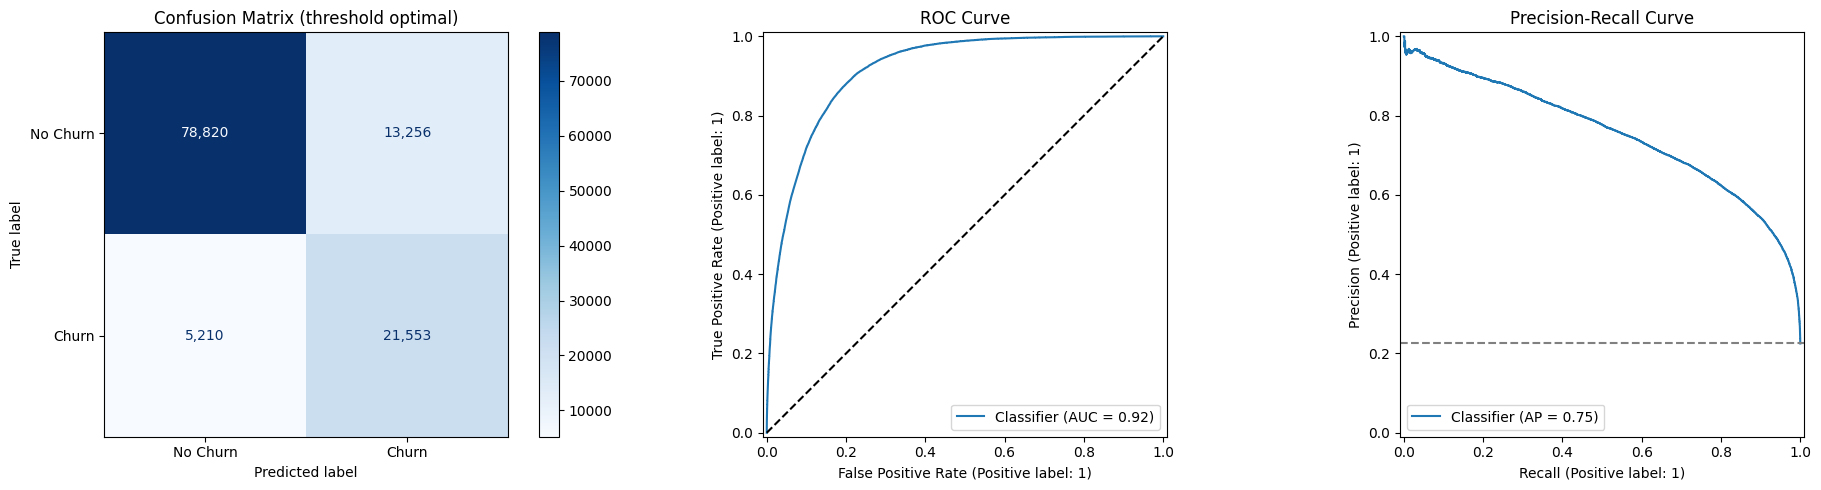

In [21]:
final_pipe = clone(search.best_estimator_)
final_pipe.fit(X_train, y_train)

proba_train = final_pipe.predict_proba(X_train)[:, 1]
proba_test = final_pipe.predict_proba(X_test)[:, 1]

print(f'PR-AUC  train: {average_precision_score(y_train, proba_train):.4f} | '
      f'test: {average_precision_score(y_test, proba_test):.4f} | '
      f'baseline acak: {y_test.mean():.4f}')
print(f'ROC-AUC test : {roc_auc_score(y_test, proba_test):.4f}')

for t, label in [(0.5, 'Threshold 0.5'), (THRESHOLD, f'Threshold optimal {THRESHOLD:.3f}')]:
    print(f'\n=== {label} ===')
    print(classification_report(y_test, (proba_test >= t).astype(int),
                                target_names=['No Churn', 'Churn'], digits=4))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= THRESHOLD).astype(int),
                                        display_labels=['No Churn', 'Churn'],
                                        cmap='Blues', values_format=',', ax=axes[0])
axes[0].set_title('Confusion Matrix (threshold optimal)')
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2])
axes[2].axhline(y_test.mean(), ls='--', c='gray')
axes[2].set_title('Precision-Recall Curve')
plt.tight_layout()
plt.show()

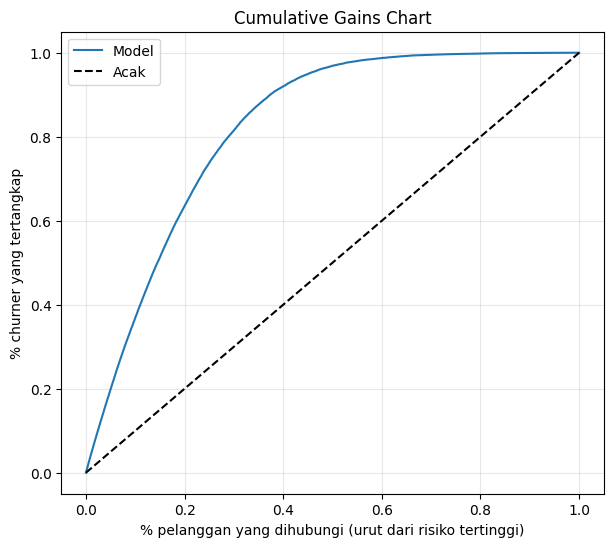

Top 10% risiko → menangkap 36.9% churner (lift 3.69x)
Top 20% risiko → menangkap 63.5% churner (lift 3.17x)
Top 30% risiko → menangkap 81.5% churner (lift 2.72x)


In [22]:
eval_df = pd.DataFrame({'proba': proba_test, 'churn': y_test.values,
                        'monthly': X_test['MonthlyCharges'].values}
                       ).sort_values('proba', ascending=False).reset_index(drop=True)
n = len(eval_df)
pct_contacted = np.arange(1, n + 1) / n
pct_captured = eval_df['churn'].cumsum() / eval_df['churn'].sum()

plt.figure(figsize=(7, 6))
plt.plot(pct_contacted, pct_captured, label='Model')
plt.plot([0, 1], [0, 1], 'k--', label='Acak')
plt.xlabel('% pelanggan yang dihubungi (urut dari risiko tertinggi)')
plt.ylabel('% churner yang tertangkap')
plt.title('Cumulative Gains Chart')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

for k in [0.1, 0.2, 0.3]:
    captured = eval_df['churn'].iloc[:int(k * n)].sum() / eval_df['churn'].sum()
    print(f'Top {int(k*100)}% risiko → menangkap {captured:.1%} churner (lift {captured/k:.2f}x)')

## Simulasi Bisnis (berdasarkan asumsi)

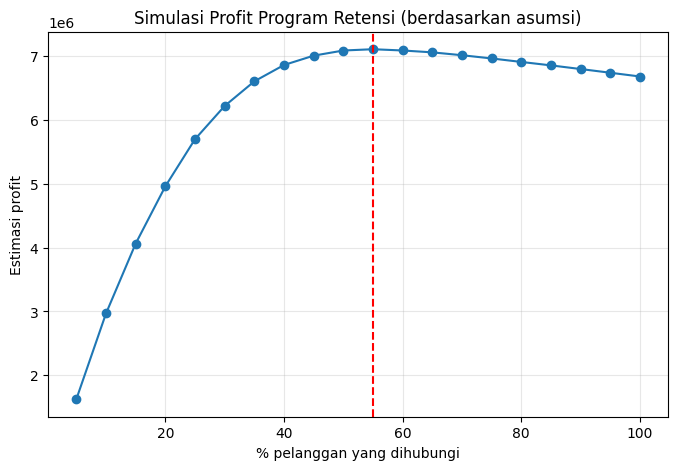

Profit maksimum saat menghubungi top 55% pelanggan berisiko (estimasi profit 7,105,555)


In [23]:
OFFER_COST = 10      # biaya insentif per pelanggan yang dihubungi (asumsi)
SAVE_RATE = 0.30     # peluang churner berhasil dipertahankan (asumsi)
MONTHS_SAVED = 12    # pendapatan terselamatkan dihitung 12 bulan (asumsi)

sim = []
for k in np.arange(0.05, 1.0001, 0.05):
    top = eval_df.iloc[:int(k * n)]
    saved_revenue = (top['churn'] * top['monthly'] * MONTHS_SAVED * SAVE_RATE).sum()
    cost = len(top) * OFFER_COST
    sim.append({'% dihubungi': k, 'Revenue terselamatkan': saved_revenue,
                'Biaya': cost, 'Profit': saved_revenue - cost})
sim = pd.DataFrame(sim)
best_k = sim.loc[sim['Profit'].idxmax()]

plt.figure(figsize=(8, 5))
plt.plot(sim['% dihubungi'] * 100, sim['Profit'], marker='o')
plt.axvline(best_k['% dihubungi'] * 100, ls='--', c='red')
plt.xlabel('% pelanggan yang dihubungi')
plt.ylabel('Estimasi profit')
plt.title('Simulasi Profit Program Retensi (berdasarkan asumsi)')
plt.grid(alpha=0.3)
plt.show()
print(f"Profit maksimum saat menghubungi top {best_k['% dihubungi']:.0%} pelanggan berisiko "
      f"(estimasi profit {best_k['Profit']:,.0f})")

## Faktor Penyebab Churn (SHAP)

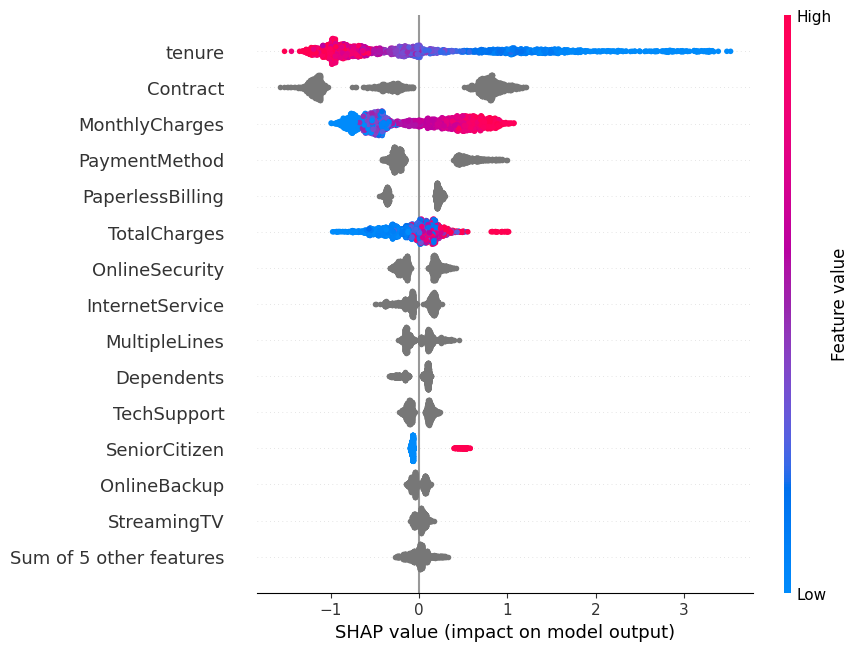

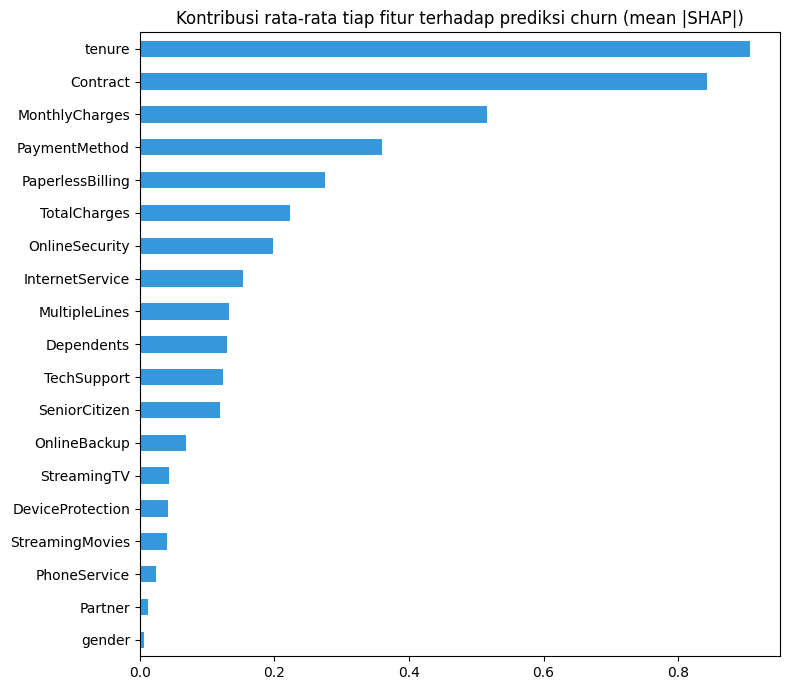

In [24]:
import shap

prep = final_pipe.named_steps['prep']
model = final_pipe.named_steps['model']
if best_name == 'CatBoost':
    model = model.model_   # ambil CatBoost asli dari dalam pembungkus

X_shap = X_test.sample(2000, random_state=RANDOM_STATE)
X_shap_t = pd.DataFrame(prep.transform(X_shap), columns=prep.get_feature_names_out())

if best_name == 'LogReg':
    explainer = shap.LinearExplainer(model, X_shap_t)
else:
    explainer = shap.TreeExplainer(model)
sv = explainer(X_shap_t)
if sv.values.ndim == 3:
    sv = sv[:, :, 1]

shap.plots.beeswarm(sv, max_display=15)

def original_feature(col):
    for c in NUM_COLS:
        if col == f'num__{c}':
            return c
    for c in CAT_COLS:
        if col.startswith(f'cat__{c}_'):
            return c
    return col  # CatBoost: nama kolom sudah asli

importance = (pd.Series(np.abs(sv.values).mean(axis=0), index=X_shap_t.columns)
              .groupby(original_feature).sum().sort_values())
importance.plot.barh(figsize=(8, 7), color='#3498db')
plt.title('Kontribusi rata-rata tiap fitur terhadap prediksi churn (mean |SHAP|)')
plt.tight_layout()
plt.show()

In [25]:
# Rata-rata SHAP per kategori: positif = menaikkan risiko churn, negatif = menurunkan
shap_df = pd.DataFrame(sv.values, columns=X_shap_t.columns, index=X_shap.index)
for col in ['Contract', 'PaymentMethod', 'InternetService', 'OnlineSecurity',
            'TechSupport', 'PaperlessBilling']:
    summary = (pd.DataFrame({'kategori': X_shap[col], 'shap': shap_df[col]})
               .groupby('kategori')['shap'].mean().sort_values(ascending=False))
    print(f'\n=== {col} ===')
    print(summary.round(3).to_string())


=== Contract ===
kategori
Month-to-month    0.817
One year         -0.316
Two year         -1.180

=== PaymentMethod ===
kategori
Electronic check             0.541
Credit card (automatic)     -0.251
Bank transfer (automatic)   -0.259
Mailed check                -0.261

=== InternetService ===
kategori
Fiber optic    0.159
No            -0.093
DSL           -0.190

=== OnlineSecurity ===
kategori
No                     0.206
No internet service   -0.161
Yes                   -0.215

=== TechSupport ===
kategori
No                     0.127
No internet service   -0.105
Yes                   -0.131

=== PaperlessBilling ===
kategori
Yes    0.224
No    -0.365


## Simpan Model

In [26]:
joblib.dump(final_pipe, 'churn_pipeline.joblib')

meta = {
    'model': best_name,
    'strategy': best_strat,
    'best_params': {k: (v if isinstance(v, (int, float, str)) or v is None else str(v))
                    for k, v in search.best_params_.items()},
    'threshold': THRESHOLD,
    'num_cols': NUM_COLS,
    'cat_cols': CAT_COLS,
    'cat_options': {c: sorted(X_train[c].unique().tolist()) for c in CAT_COLS},
    'num_ranges': {c: [float(X_train[c].min()), float(X_train[c].max())] for c in NUM_COLS},
    'test_metrics': {
        'pr_auc': float(average_precision_score(y_test, proba_test)),
        'roc_auc': float(roc_auc_score(y_test, proba_test)),
    },
}
with open('churn_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('Tersimpan: churn_pipeline.joblib & churn_meta.json')

Tersimpan: churn_pipeline.joblib & churn_meta.json


# Kesimpulan


## 1. Perbandingan Model
Sebanyak 7 model (termasuk baseline Dummy) diuji dengan 3 strategi penanganan imbalance (18 kombinasi) menggunakan 5-fold cross-validation pada 100.000 sampel data latih.

| Peringkat | Model | Strategi | PR-AUC (CV) | Waktu fit (detik) |
|---|---|---|---|---|
| 1 | CatBoost | none | 0,7427 | 67,8 |
| 2 | LightGBM | weight | 0,7421 | 1,2 |
| 3 | XGBoost | weight | 0,7402 | 1,2 |
| 4 | Random Forest | none | 0,7338 | 3,4 |
| 5 | Logistic Regression | none | 0,7187 | 0,7 |
| 6 | Decision Tree | weight | 0,7168 | 1,0 |
| – | Dummy | none | 0,2252 | – |

- Seluruh model jauh melampaui baseline Dummy (0,2252), sehingga model benar-benar mempelajari pola churn.
- Model **boosting (CatBoost, LightGBM, XGBoost) unggul** dibanding model lain. Namun selisih di antara ketiganya (< 0,003) lebih kecil dari standar deviasi antar fold (≈ 0,005), sehingga performanya praktis setara. LightGBM sekitar 55× lebih cepat dari CatBoost dan dapat menjadi alternatif bila kecepatan training diprioritaskan.
- **SMOTE tidak pernah menjadi strategi terbaik** pada model mana pun. Setelah diterapkan dengan benar (hanya pada data latih), SMOTE tidak meningkatkan PR-AUC dibanding tanpa penanganan atau *class weighting*.

## 2. Hyperparameter Tuning
RandomizedSearchCV (20 kombinasi, 3-fold) pada CatBoost menghasilkan parameter terbaik `learning_rate=0,05`, `depth=6`, `l2_leaf_reg=5`, `iterations=800`, dengan PR-AUC CV 0,7427. Nilai ini sama dengan konfigurasi awal, yang menunjukkan bahwa pengaturan default CatBoost sudah mendekati optimal untuk dataset ini.

## 3. Performa pada Data Uji
Model final dilatih pada seluruh data latih (475.355 baris) dan dievaluasi pada data uji (118.839 baris) dengan distribusi kelas asli (22,5% churn):
- **PR-AUC test: 0,7544** (3,35× lebih baik dari baseline acak 0,2252)
- **ROC-AUC test: 0,9164**
- PR-AUC train 0,7578 vs test 0,7544 (selisih 0,0034), sehingga **model tidak mengalami overfitting**.

## 4. Pemilihan Threshold
Threshold dipilih menggunakan prediksi *out-of-fold* pada data latih (bukan data uji) dengan memaksimalkan F1, menghasilkan **threshold 0,33**.

| Metrik (kelas Churn) | Threshold 0,5 | Threshold 0,33 |
|---|---|---|
| Recall | 0,6411 | **0,8053** |
| Precision | 0,7119 | 0,6192 |
| F1-score | 0,6746 | **0,7001** |

Dengan threshold 0,33, model menangkap **80,5% pelanggan yang benar-benar churn**, dan sekitar 6 dari 10 pelanggan yang ditandai berisiko memang churn. Untuk program retensi, menangkap lebih banyak churner umumnya lebih penting, karena biaya kehilangan pelanggan lebih besar dari biaya insentif.

## 5. Efektivitas Penargetan (Cumulative Gains)
| Pelanggan yang dihubungi (risiko tertinggi) | Churner yang tertangkap | Lift |
|---|---|---|
| Top 10% | 36,9% | 3,69× |
| Top 20% | 63,5% | 3,17× |
| Top 30% | 81,5% | 2,72× |

Dengan hanya menghubungi 20% pelanggan berisiko tertinggi, perusahaan dapat menjangkau hampir dua pertiga dari seluruh pelanggan yang akan churn.

## 6. Faktor Penyebab Churn (SHAP)
Nilai SHAP positif berarti menaikkan risiko churn, negatif berarti menurunkan.

- **tenure** adalah faktor paling berpengaruh: pelanggan baru (tenure rendah) memiliki risiko churn jauh lebih tinggi, sedangkan pelanggan lama cenderung bertahan.
- **Contract** adalah faktor kedua terbesar: kontrak **Month-to-month menaikkan risiko** (SHAP +0,82), sedangkan kontrak One year (−0,32) dan terutama **Two year (−1,18)** sangat menurunkan risiko.
- **MonthlyCharges**: tagihan bulanan tinggi meningkatkan risiko churn.
- **PaymentMethod**: **Electronic check** satu-satunya metode yang menaikkan risiko (+0,54); tiga metode lainnya (credit card otomatis, bank transfer otomatis, mailed check) sama-sama menurunkan risiko (≈ −0,25).
- **PaperlessBilling**: pelanggan dengan tagihan paperless lebih berisiko (+0,22) dibanding yang tidak (−0,37).
- **OnlineSecurity** dan **TechSupport**: pelanggan **tanpa** layanan ini lebih berisiko (+0,21 dan +0,13).
- **InternetService**: pengguna **Fiber optic** lebih berisiko (+0,16) dibanding DSL (−0,19).
- **SeniorCitizen**: pelanggan lansia memiliki risiko churn lebih tinggi.
- **gender**, **Partner**, dan **PhoneService** hampir tidak berpengaruh.

## 7. Simulasi Bisnis
Dengan asumsi biaya insentif 10 per pelanggan, tingkat keberhasilan retensi 30%, dan pendapatan terselamatkan selama 12 bulan, profit maksimum (≈ 7,1 juta pada data uji) dicapai saat menghubungi **top 55%** pelanggan berisiko. Kurva profit relatif datar pada rentang 45–70%, sehingga menargetkan sekitar 45% pelanggan sudah memberikan profit yang hampir sama dengan jumlah kontak lebih sedikit. Hasil ini sangat bergantung pada asumsi biaya dan tingkat keberhasilan, sehingga perlu divalidasi dengan data biaya aktual perusahaan.

## 8. Rekomendasi Bisnis
1. **Dorong migrasi ke kontrak jangka panjang.** Tawarkan diskon atau bonus bagi pelanggan *month-to-month* yang beralih ke kontrak 1–2 tahun. Kontrak dua tahun adalah faktor penurun risiko terkuat.
2. **Fokus pada pelanggan baru.** Risiko churn tertinggi ada di bulan-bulan awal berlangganan, sehingga perlu program *onboarding* (misalnya follow-up di bulan pertama dan ketiga).
3. **Dorong pembayaran otomatis.** Pengguna *electronic check* jauh lebih berisiko. Insentif kecil untuk beralih ke autodebet kartu kredit atau bank dapat menurunkan risiko churn.
4. **Bundel layanan Online Security dan Tech Support** untuk pelanggan berisiko, misalnya gratis 3 bulan. Pelanggan yang memiliki layanan ini cenderung lebih loyal.
5. **Evaluasi pengalaman pelanggan Fiber optic.** Risiko yang lebih tinggi pada segmen ini, terutama dengan tagihan bulanan tinggi, mengindikasikan perlunya kajian harga atau kualitas layanan.
6. **Gunakan skor risiko model** untuk mengurutkan prioritas kontak tim retensi, dimulai dari pelanggan dengan probabilitas churn tertinggi.

## 9. Perbaikan dari Versi Sebelumnya
Versi awal menerapkan SMOTE sebelum pembagian data, sehingga data uji mengandung sampel sintetis dan berdistribusi 50:50. Akibatnya hasil evaluasi terlalu optimis (accuracy 88,88%, AUC 0,955). Versi ini memperbaiki urutan tersebut sehingga data uji mencerminkan kondisi nyata. Accuracy turun menjadi 86,1% (threshold 0,5), tetapi angka ini merupakan estimasi yang jujur terhadap performa model pada data baru.